# Laboratorio Evaluado: WBCD y Evaluación Multimodelo

**Reto Autónomo: Clínica Oncológica**

Eres el Consultor IA de un hospital. El dataset WBCD contiene radios y perímetros de células. Debes entrenar k-NN y Árboles de Decisión, y validar qué pasa si no escalas los datos.

## 1. Carga de Datos y Exploración

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score, ConfusionMatrixDisplay

# Nombre: Cruz Trujillo Brayann Limberth
# Materia: Int201

medidas = ['radio', 'textura', 'perimetro', 'area', 'suavidad', 'compacidad', 'concavidad', 'puntos_concavos', 'simetria', 'dim_fractal']
columnas = ['id', 'diagnosis'] + [f'{m}_{s}' for s in ['media', 'error', 'peor'] for m in medidas]

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
try:
    df_wbcd = pd.read_csv(URL, header=None, names=columnas)
    print("Cargado desde UCI.")
except Exception:
    from sklearn.datasets import load_breast_cancer
    d = load_breast_cancer()
    df_wbcd = pd.DataFrame(d.data, columns=columnas[2:])
    df_wbcd.insert(0, 'diagnosis', np.where(d.target == 0, 'M', 'B'))  # en sklearn 0 = maligno
    df_wbcd.insert(0, 'id', range(len(df_wbcd)))
    print("UCI no accesible desde este entorno: se usó la copia idéntica de sklearn.")

print(df_wbcd.shape)
print(df_wbcd['diagnosis'].value_counts())
df_wbcd.iloc[:, :6].head()

Cargado desde UCI.
(569, 32)
diagnosis
B    357
M    212
Name: count, dtype: int64


,id,diagnosis,radio_media,textura_media,perimetro_media,area_media
0,842302,M,17.99,10.38,122.80,1001.0
1,842517,M,20.57,17.77,132.90,1326.0
2,84300903,M,19.69,21.25,130.00,1203.0
3,84348301,M,11.42,20.38,77.58,386.1
4,84358402,M,20.29,14.34,135.10,1297.0


## 2. Preprocesamiento

In [3]:
# 1) Diagnosis M/B -> 1/0 (1 = Maligno, la clase que no queremos perder)
df_wbcd['diagnosis'] = df_wbcd['diagnosis'].map({'M': 1, 'B': 0})

# 2) X (features) e y (target); se descarta el id, que no es una medida clínica
X = df_wbcd.drop(columns=['id', 'diagnosis'])
y = df_wbcd['diagnosis']

# 3) 80% train / 20% test (estratificado para conservar la proporción M/B)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Train: {X_train.shape[0]} pacientes | Test: {X_test.shape[0]} pacientes")
print(f"% malignos -> train: {y_train.mean():.1%} | test: {y_test.mean():.1%}")

Train: 455 pacientes | Test: 114 pacientes
% malignos -> train: 37.4% | test: 36.8%


## 3. Escalamiento (Solo para k-NN)

In [4]:
# fit_transform en train (aprende media y desviación) y solo transform en test (evita fuga de datos)
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

# Para ver por qué importa: rangos de dos variables SIN escalar
print(X_train[['area_media', 'suavidad_media']].describe().loc[['min', 'max']].round(3))

     area_media  suavidad_media
min       143.5           0.063
max      2501.0           0.163


## 4. Modelado y Matrices de Confusión


k-NN (escalado)
[[71  1]
 [ 4 38]]   (filas = real B/M, columnas = predicho B/M)

k-NN (SIN escalar)
[[71  1]
 [ 9 33]]   (filas = real B/M, columnas = predicho B/M)

Árbol (sin escalar)
[[70  2]
 [ 8 34]]   (filas = real B/M, columnas = predicho B/M)

Árbol (escalado)
[[70  2]
 [ 8 34]]   (filas = real B/M, columnas = predicho B/M)


,Exactitud,Recall (maligno),Precisión,Falsos Negativos,Falsos Positivos
Modelo,,,,,
k-NN (escalado),0.956,0.905,0.974,4,1
k-NN (SIN escalar),0.912,0.786,0.971,9,1
Árbol (sin escalar),0.912,0.810,0.944,8,2
Árbol (escalado),0.912,0.810,0.944,8,2


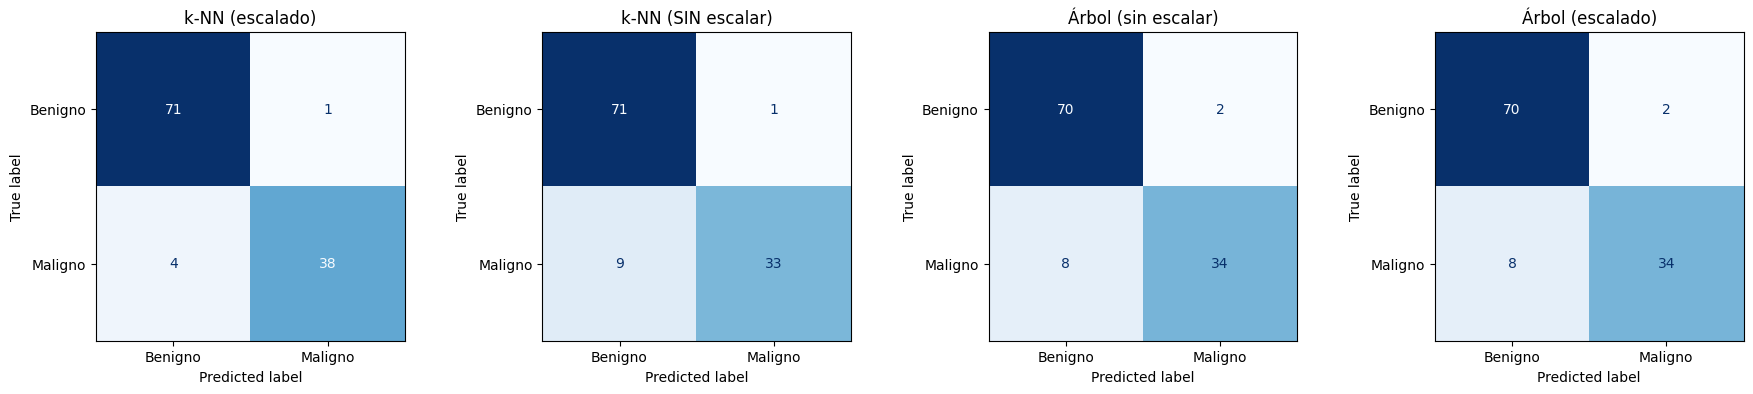

In [5]:
knn = KNeighborsClassifier(n_neighbors=5).fit(X_train_esc, y_train)
arbol = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train, y_train)  # el árbol no necesita escalado

# Experimento del reto: ¿qué pasa si NO escalamos?
knn_sin = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)
arbol_esc = DecisionTreeClassifier(max_depth=4, random_state=42).fit(X_train_esc, y_train)

modelos = {
    'k-NN (escalado)':        (knn,       X_test_esc),
    'k-NN (SIN escalar)':     (knn_sin,   X_test),
    'Árbol (sin escalar)':    (arbol,     X_test),
    'Árbol (escalado)':       (arbol_esc, X_test_esc),
}
filas = []
for nombre, (m, Xt) in modelos.items():
    pred = m.predict(Xt)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    print(f"\n{nombre}\n{confusion_matrix(y_test, pred)}   (filas = real B/M, columnas = predicho B/M)")
    filas.append({'Modelo': nombre, 'Exactitud': accuracy_score(y_test, pred),
                  'Recall (maligno)': recall_score(y_test, pred), 'Precisión': precision_score(y_test, pred),
                  'Falsos Negativos': fn, 'Falsos Positivos': fp})
res = pd.DataFrame(filas).set_index('Modelo')
display(res.round(3))

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, (nombre, (m, Xt)) in zip(axes, modelos.items()):
    ConfusionMatrixDisplay.from_estimator(m, Xt, y_test, display_labels=['Benigno', 'Maligno'], cmap='Blues', ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

## Evaluación Teórica / Decisión de Negocios

1. En este escenario médico, ¿qué implica un Error Tipo II (Falso Negativo) y por qué cuesta vidas?
2. ¿Por qué crees que el Árbol de Decisión no falló estrepitosamente incluso si no hubieses escalado los datos?

*Escribe tu respuesta aquí:*

### Respuesta 1: Error Tipo II (Falso Negativo)

Un falso negativo es una paciente con tumor **maligno** a la que el modelo clasifica como **benigna**. Se le dice "está sana" cuando no lo está, por lo que no recibe biopsia ni tratamiento a tiempo. El cáncer progresa y el diagnóstico tardío reduce mucho la supervivencia: ese retraso es lo que cuesta vidas.

Es el error más grave del problema. Un falso positivo (benigno clasificado como maligno) causa angustia y una biopsia innecesaria, pero se corrige con más pruebas. Por eso en este contexto no basta mirar la exactitud: hay que priorizar el **recall (sensibilidad) de la clase maligna**, que es la columna "Falsos Negativos" de la tabla, aun a costa de más falsos positivos.

### Respuesta 2: ¿Por qué el Árbol no falló sin escalar?

El árbol decide con preguntas del tipo `variable ≤ umbral` y busca cada umbral **dentro de una sola variable a la vez**. Escalar es una transformación monótona (resta una media y divide por una desviación), así que el orden de los pacientes en cada variable no cambia, y los cortes elegidos separan exactamente los mismos grupos. Por eso el árbol da el mismo resultado con o sin escalar (se ve en la tabla: "Árbol (sin escalar)" y "Árbol (escalado)" coinciden).

k-NN, en cambio, usa **distancias euclidianas entre todas las variables juntas**. Sin escalar, `area_media` (cientos o miles) domina la distancia y variables como `suavidad_media` (≈0.1) quedan ignoradas, lo que empeora el resultado frente a k-NN escalado.

**Recomendación al hospital:** priorizar el modelo con menos falsos negativos (ver tabla), escalar siempre antes de usar k-NN, y validar con más datos o validación cruzada antes de usarlo en clínica, porque el test tiene solo ~114 pacientes.